# Tiamat

Aluno: Ricardo Pereira Lourenço de Carvalho

Docente: Daniel R. Cassar

Instituiçao: Ilum Escola de Ciência

## Introdução

### Contexto e problema

Fraudes em cartões de crédito causam prejuízos financeiros a clientes, bancos e comerciantes. Detectá-las automaticamente é difícil por dois motivos. O primeiro é o desbalanceamento extremo: as fraudes são uma fração minúscula das transações, então um modelo que classifica tudo como "normal" já tem acurácia altíssima sem detectar nenhuma fraude. O segundo é o custo assimétrico dos erros: deixar passar uma fraude (falso negativo) causa prejuízo direto, mas bloquear uma transação legítima (falso positivo) prejudica o cliente e a confiança no sistema. Por isso, este trabalho dá atenção especial à **precisão** e usa a **PR-AUC** como métrica de seleção de modelos.

### Conjunto de dados

Foi utilizado o conjunto *Credit Card Fraud Detection* (`creditcard.csv`), que contém transações de cartões de crédito realizadas por clientes europeus e rotuladas como normais (`= 0`) ou fraudulentas (` = 1`). Os atributos V1 a V28 são componentes principais obtidos por PCA e anonimizados pelos autores do conjunto por questões de confidencialidade, de modo que não têm interpretação direta. Neste trabalho foram usados como atributos apenas `V1`–`V28`, e a coluna `Time`  foi deixada de fora. O alvo é a coluna `Class`. A quantidade de exemplos e a proporção de fraudes são apresentadas na seção *Conjunto de Dados*.

### Objetivo

Comparar o desempenho de diferentes algoritmos de aprendizado de máquina na detecção de fraudes, com hiperparâmetros otimizados pelo Optuna e avaliação por validação cruzada, e identificar qual combinação de algoritmo, tratamento do desbalanceamento e redução de dimensionalidade apresenta o melhor desempenho.

### Abordagem

- **Separação dos dados:** o conjunto é dividido em treino e teste (cerca de 10% para teste) com StratifiedGroupKFold. Linhas quase idênticas são agrupadas, para que não apareçam ao mesmo tempo no treino e no teste, o que inflaria artificialmente o desempenho.
- **Baseline:** um DummyClassifier, que serve de referência mínima.
- **Algoritmos:** Regressão Logística, KNN, Random Forest, Hist. Gradient Boosting e MLP.
- **Validação cruzada:** 5 folds estratificados e agrupados, idênticos para todos os algoritmos, com a PR-AUC como métrica de comparação.
- **Otimização:** 100 tentativas do Optuna por algoritmo, que ajusta ao mesmo tempo os hiperparâmetros do modelo, o grau de subamostragem da classe majoritária e a estratégia de redução de dimensionalidade (nenhuma, PCA ou seleção de atributos, incluindo o número de componentes ou de atributos mantidos).
- **Avaliação final:** o melhor pipeline de cada algoritmo é avaliado uma única vez no conjunto de teste, e o limiar de decisão do melhor modelo é ajustado apenas com previsões fora da amostra obtidas na validação cruzada.

### Estrutura do caderno

O caderno apresenta o conjunto de dados e a análise exploratória, as métricas de desempenho, o modelo baseline, a regressão logística inicial, a comparação dos algoritmos com Optuna e, por fim, a avaliação no teste, seguida da conclusão e das referências.

## Bibliotecas Utilizadas

In [1]:
# Bibliotecas para DataSet
import pandas as pd
import numpy as np

# Bibliotecas para Gráficos
import seaborn as sns
import matplotlib.pyplot as plt

# Biblioteca Scikit para os modelos
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, average_precision_score, recall_score,
    precision_score, fbeta_score, precision_recall_curve, ConfusionMatrixDisplay,
)

# Produto Cartesiano para combinações de hiperparâmetros
from itertools import product

# Paralelização
from joblib import Parallel, delayed

# Optuna e balanceamento
import optuna
from optuna.samplers import TPESampler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

## Conjunto de Dados

O conjunto contém 284.807 transações de cartão de crédito e 31 colunas:

- **Time:** segundos decorridos desde a primeira transação do conjunto.
- **V1–V28:** atributos numéricos obtidos por PCA e anonimizados por confidencialidade, sem interpretação direta.
- **Amount:** valor da transação.
- **Class:** alvo, com 0 para transação normal e 1 para fraude.

Todas as colunas são numéricas e o conjunto não tem valores ausentes, então o dropna() não removeu nenhuma linha.

In [40]:
df_dados = pd.read_csv("creditcard.csv")
df_dados = df_dados.dropna()

df_dados

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


### Visualização da porcentagem de fraudes

O gráfico abaixo mostra o desbalanceamento entre as classes, em escala logarítmica. As fraudes são uma fração minúscula das transações, o que justifica o uso de métricas como a PR-AUC e de estratégias de balanceamento.

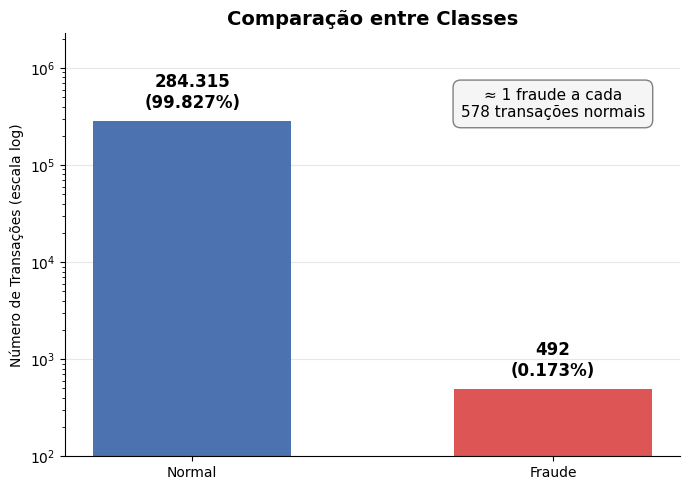

In [4]:
contagem = df_dados["Class"].value_counts().sort_index()
n_normal, n_fraude = contagem[0], contagem[1]
total = contagem.sum()

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["Normal", "Fraude"], [n_normal, n_fraude],
                color=["#4C72B0", "#DD5555"], width=0.55)

ax.set_yscale("log")
ax.set_ylim(100, n_normal * 8)

for barra, n in zip(barras, [n_normal, n_fraude]):
    ax.text(barra.get_x() + barra.get_width() / 2, n * 1.25,
            f"{n:,}".replace(",", ".") + f"\n({n / total * 100:.3f}%)",
            ha="center", va="bottom", fontsize=12, fontweight="bold")

ax.text(1, n_normal * 1.5,
        f"≈ 1 fraude a cada\n{n_normal / n_fraude:.0f} transações normais",
        ha="center", va="center", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="gray"))

ax.set_title("Comparação entre Classes", fontsize=14, fontweight="bold")
ax.set_ylabel("Número de Transações (escala log)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()

O histograma compara a distribuição do valor das transações entre as duas classes, com eixo x em escala logarítmica. Cada classe foi normalizada pela sua própria quantidade de transações, para que o desbalanceamento não esconda a comparação.

- As transações normais se concentram em valores intermediários, aproximadamente entre 10 e 100.
- As fraudes têm um padrão diferente: um pico muito alto perto de 1 (cerca de 24% das fraudes) e outro perto de 100, além de uma cauda maior em valores altos, acima de 100.
- As duas distribuições se sobrepõem bastante, então o valor sozinho não separa fraude de transação normal.

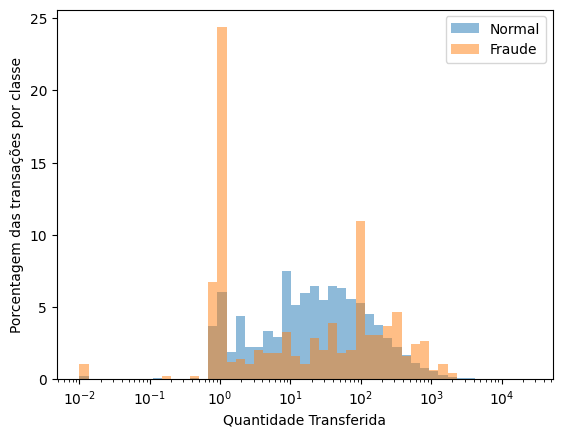

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fraudes = df_dados[df_dados["Class"] == 1]
normais = df_dados[df_dados["Class"] == 0]

bins = np.logspace(-2, np.log10(df_dados["Amount"].max()), 50)

peso_normais = np.ones(len(normais)) / len(normais) * 100
peso_fraudes = np.ones(len(fraudes)) / len(fraudes) * 100

plt.hist(normais["Amount"], bins=bins, weights=peso_normais, alpha=0.5, label="Normal")
plt.hist(fraudes["Amount"], bins=bins, weights=peso_fraudes, alpha=0.5, label="Fraude")
plt.xscale("log")
plt.xlabel("Quantidade Transferida")
plt.ylabel("Porcentagem das transações por classe")
plt.legend()
plt.show()

## Separação dos Dados de Teste e Treino

Separamos então nosso target de nossos atributos.

In [6]:
ATRIBUTOS = ["V1","V2","V3","V4", "V5",	"V6","V7","V8",	"V9", "V10",
             "V11","V12", "V13", "V14", "V15", "V16","V17", "V18", "V19", "V20",
             "V21",	"V22",	"V23",	"V24",	"V25",	"V26",	"V27",	"V28", "Amount"]
TARGET = ["Class"]

A quantidade de dinheiro tranferido foi colocada na escala `log` para não ter um peso desbalanceado em modelos que medem distância, por exemplo, como o K-NN.

In [7]:
df_dados["Amount"] = np.log1p(df_dados["Amount"])

Separamos os dados em teste e treino atráves do Scikit. Cerca de $10\%$ dos dados foram separados como dados de teste, e padronizados por uma semente aleatória com o objetivo de replicabilidade. É possível visualizar abaixo quantos grupos foram unicos grupos foram formados e quantas linhas duplicadas foram achadas.

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

CASAS_DECIMAIS = 6

TAMANHO_TESTE = 0.1
SEMENTE_ALEATORIA = 61455

df_arredondado = df_dados.copy()
df_arredondado[ATRIBUTOS] = df_arredondado[ATRIBUTOS].round(CASAS_DECIMAIS)

grupos = df_arredondado.groupby(ATRIBUTOS).ngroup()

print(f"Número de exemplos: {len(df_dados)}")
print(f"Grupos únicos: {grupos.nunique()}")
print(f"Linhas duplicadas nos atributos: {df_dados.duplicated(subset=ATRIBUTOS).sum()}")

sgkf = StratifiedGroupKFold(
    n_splits=round(1 / TAMANHO_TESTE),
    shuffle=True,
    random_state=SEMENTE_ALEATORIA,
)

Número de exemplos: 284807
Grupos únicos: 275663
Linhas duplicadas nos atributos: 9144


Indicamos então os grupos de treino e teste de acordo com grupos identificados nas células acima e é possivel visualizar a porcentagem de fraudes no treino e teste.

In [9]:
indices_treino, indices_teste = next(
    sgkf.split(df_dados[ATRIBUTOS], df_dados["Class"], groups=grupos)
)

df_treino = df_dados.iloc[indices_treino]
df_teste = df_dados.iloc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

X_treino = X_treino.astype(np.float32)
X_teste = X_teste.astype(np.float32)

print(f"% de fraudes no treino: {df_treino['Class'].mean() * 100:.3f}")
print(f"% de fraudes no teste:  {df_teste['Class'].mean() * 100:.3f}")
print(f"Fraudes no teste: {df_teste['Class'].sum()}")
print(f"Grupos em comum entre treino e teste: "
      f"{len(set(grupos.iloc[indices_treino]) & set(grupos.iloc[indices_teste]))}")

% de fraudes no treino: 0.175
% de fraudes no teste:  0.151
Fraudes no teste: 43
Grupos em comum entre treino e teste: 0


### Métricas de Desempenho

Com base na matriz de confusão, podemos definir métricas para problemas de classificação. A matriz de confusão em problemas binários tem o seguinte formato:

| |Valor predito = 1|Valor predito = 0|
|:-:|:-:|:-:|
| <b>Valor real = 1</b>|VP|FN|
| <b>Valor real = 0</b>|FP|VN|

Onde:

-   **VP** ou <font color="blue">Verdadeiro positivo</font> (*true positive*): rótulo real é 1 e a previsão foi 1.
-   **FP** ou <font color="red">Falso positivo</font> (*false positive*): rótulo real é 0 e a previsão foi 1.
-   **VN** ou <font color="blue">Verdadeiro negativo</font> (*true negative*): rótulo real é 0 e a previsão foi 0.
-   **FN** ou <font color="red">Falso negativo</font> (*false negative*): rótulo real é 1 e a previsão foi 0.

Neste caderno será usado então:

### PR-AUC

A **PR-AUC** (*Precision-Recall Area Under the Curve*, ou área sob a curva Precisão-Recall) resume em um único número o quanto um modelo consegue encontrar as fraudes (recall) sem classificar transações legítimas como fraude (precisão).

**Precisão e recall**

$$
\mathrm{Precisão = \frac{VP}{VP + FP}} \qquad \mathrm{Recall = \frac{VP}{VP + FN}}
$$

- **Precisão:** das transações que o modelo apontou como fraude, quantas realmente eram.
- **Recall:** de todas as fraudes existentes, quantas o modelo encontrou.

**A curva Precisão-Recall**

O modelo não responde apenas "fraude" ou "normal": ele atribui a cada transação uma **probabilidade** de ser fraude, e a decisão final depende de um **limiar**. Se o limiar é baixo, o modelo marca muitas transações como fraude, de modo que o recall sobe e a precisão cai. Se o limiar é alto, acontece o contrário. A curva Precisão-Recall é construída variando o limiar de 0 a 1 e registrando o par (recall, precisão) em cada ponto. A PR-AUC é a **área sob essa curva**, calculada neste trabalho pela função `average_precision_score` do Scikit-learn.

**Como interpretar**

- Quanto mais próxima de **1**, melhor: o modelo mantém alta precisão mesmo encontrando quase todas as fraudes.
- O valor de referência de um modelo sem poder preditivo é a **proporção de fraudes** nos dados (aqui, cerca de $0{,}17\%$), e não $0{,}5$. O baseline obtém exatamente esse valor.

**Por que usar a PR-AUC neste problema**

1. **Classes muito desbalanceadas.** Com cerca de 1 fraude a cada 600 transações, a acurácia e a ROC-AUC podem parecer excelentes mesmo com um modelo ruim, pois o enorme número de transações normais classificadas corretamente domina o resultado. A PR-AUC ignora os verdadeiros negativos e foca apenas na classe de interesse.

   
2. **Não depende de limiar.** Permite comparar algoritmos antes de decidir qual limiar usar. Por isso ela é a métrica de seleção na validação cruzada, e o limiar só é ajustado depois, para o melhor modelo.


3. **Penaliza falsos positivos.** alinhada ao objetivo de não bloquear transações legítimas, já que a precisão está embutida na métrica.


### F-beta e F0,5

O **F-beta** é uma métrica que combina precisão e recall em um único número, permitindo dar mais peso a um ou a outro:

$$
F_\beta = (1 + \beta^2)\cdot\frac{\text{Precisão}\cdot\text{Recall}}{\beta^2\cdot\text{Precisão} + \text{Recall}}
$$

O parâmetro $\beta$ controla a importância do recall em relação à precisão:

- $\beta = 1$ (F1): precisão e recall têm o mesmo peso.
- $\beta > 1$ (por exemplo, F2): o recall pesa mais, o que é útil quando deixar passar um positivo (falso negativo) é mais grave.
- $\beta < 1$ (por exemplo, F0,5): a precisão pesa mais, o que é útil quando um falso positivo é mais grave.

**Por que F0,5 neste trabalho?**

Em fraudes, bloquear uma transação legítima (falso positivo) prejudica o cliente e a confiança no sistema, então queremos que os alertas sejam confiáveis. Com $\beta = 0{,}5$, a precisão tem peso 4 vezes maior que o recall ($1/\beta^2 = 4$), e a fórmula fica:

$$
F_{0,5} = 1{,}25\cdot\frac{\text{Precisão}\cdot\text{Recall}}{0{,}25\cdot\text{Precisão} + \text{Recall}}
$$

**Como foi usado**

O limiar de decisão do melhor modelo foi escolhido como o valor que maximiza o F0,5 nas previsões fora da amostra da validação cruzada. Esse limiar foi então aplicado sem alterações ao conjunto de teste. Isso favorece limiares altos, que geram poucos alertas e com alta precisão, ao custo de um recall menor.

**Interpretação**

Quanto mais próximo de 1, melhor. Um F0,5 alto só é possível quando a precisão é alta e o recall não é muito baixo, já que, se um dos dois for próximo de zero, o F-beta também cai.

## Modelos Diferentes

### Hist Gradient Boosting

#### 1. Ideia geral

O **Gradient Boosting** constrói um modelo forte somando várias árvores de decisão **fracas** (rasas), uma de cada vez. Cada nova árvore tenta **corrigir os erros** do conjunto anterior.

O **Hist Gradient Boosting** é uma versão otimizada que usa **histogramas** para acelerar muito o treino em bases grandes.

#### 2. Como funciona o boosting

1. Começa com uma previsão inicial simples (ex.: a média do target, em regressão).
2. Calcula o erro (resíduo) de cada exemplo.
3. Treina uma árvore para prever esse erro.
4. Soma a previsão da árvore ao modelo, multiplicada pela **taxa de aprendizado** (`learning_rate`).
5. Repete os passos 2–4 até atingir o número máximo de iterações ou até o **early stopping**.

$$
F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)
$$

- $F_m$: modelo após $m$ árvores
- $h_m$: nova árvore (treinada nos resíduos/gradientes)
- $\eta$: taxa de aprendizado

> O "gradient" vem do fato de as árvores serem ajustadas ao **gradiente negativo da função de perda**. 


#### 3. O que é o "Hist"

No Gradient Boosting tradicional, para cada divisão de cada nó a árvore testa **todos os valores possíveis** de cada atributo. Isso é custoso.

No Hist Gradient Boosting:

1. Cada atributo contínuo é **discretizado em bins**.
2. A árvore constrói um **histograma** com a soma dos gradientes por bin.
3. Os cortes candidatos passam a ser apenas as **fronteiras dos bins**.

Vantagens:

- Treino **muito mais rápido**: a complexidade passa a depender do número de bins, não do número de valores distintos.
- Menos memória

#### 5. Principais hiperparâmetros (scikit-learn)

| Hiperparâmetro | O que controla |
|---|---|
| `learning_rate` | Contribuição de cada árvore. Menor = mais robusto, mas precisa de mais iterações. |
| `max_iter` | Número máximo de árvores. |
| `max_leaf_nodes` | Complexidade de cada árvore. |
| `max_depth` | Profundidade máxima. |
| `min_samples_leaf` | Mínimo de exemplos por folha (evita sobreajuste). |
| `max_bins` | Número de bins do histograma. |
| `early_stopping` | Ativa a parada antecipada. |
| `class_weight` | Peso por classe (útil em dados desbalanceados). |

#### 7. Vantagens e desvantagens

**Vantagens**

- Rápido e escalável para muitos exemplos.
- Lida com NaN e categóricos sem pré-processamento.
- Normalmente tem excelente desempenho em dados tabulares.
- Não exige normalização dos atributos.

**Desvantagens**

- Muitos hiperparâmetros para ajustar (bom uso de Optuna ou busca aleatória).
- Pode sobreajustar com `learning_rate` alto e muitas árvores.
- Menos interpretável que uma árvore única.

### MLP (Multilayer Perceptron)

#### 1. Ideia geral

O **MLP** é uma rede neural artificial feedforward formada por camadas de neurônios totalmente conectados. Ele aprende uma função não linear que mapeia os atributos $X$ no target $y$, ajustando seus pesos por **descida do gradiente**.

#### 2. Estrutura

- **Camada de entrada**: um neurônio por atributo.
- **Camadas ocultas**: onde ocorre a transformação não linear.
- **Camada de saída**: um neurônio (regressão ou classificação binária) ou um por classe (multiclasse).

Cada neurônio calcula uma soma ponderada das entradas e aplica uma **função de ativação**:

$$
a = \phi\left(\sum_i w_i x_i + b\right)
$$

- $w_i$: pesos
- $b$: viés (*bias*)
- $\phi$: função de ativação

#### 3. Funções de ativação

| Ativação | Fórmula / comportamento | Observação |
|---|---|---|
| `relu` | $\max(0, x)$ | Padrão. Rápida, evita saturação. |
| `tanh` | tangente hiperbólica, saída em $(-1, 1)$ | Pode saturar. |
| `logistic` | sigmoide, saída em $(0, 1)$ | Pode saturar. |
| `identity` | $f(x) = x$ | Equivale a um modelo linear. |

Sem ativação não linear, várias camadas colapsam em uma única transformação linear.

#### 4. Como o MLP aprende

1. **Forward pass**: os dados atravessam a rede e produzem uma previsão.
2. **Função de perda**: mede o erro.
   - Regressão: erro quadrático médio.
   - Classificação: entropia cruzada (*log loss*).
3. **Backpropagation**: calcula o gradiente da perda em relação a cada peso.
4. **Atualização dos pesos** por um otimizador:

$$
w \leftarrow w - \eta \, \frac{\partial L}{\partial w}
$$

5. Repete por várias **épocas** (passagens completas pelos dados), em *mini-batches*.

#### 5. Otimizadores

- `adam` (padrão): adaptativo, bom em bases grandes.
- `sgd`: gradiente descendente estocástico, aceita `momentum`.
- `lbfgs`: método quasi-Newton, bom para bases **pequenas**.

#### 6. Pré-processamento

- **Normalização é obrigatória**: o MLP é sensível à escala. Use `StandardScaler` ou `MinMaxScaler`, ajustado **apenas no treino**.
- **Categóricos**: precisam de codificação (ex.: one-hot).
- **NaN**: não são aceitos, é preciso imputar.
- A inicialização dos pesos é aleatória, então fixe `random_state` para reprodutibilidade.

#### 7. Principais hiperparâmetros (scikit-learn)

| Hiperparâmetro | O que controla |
|---|---|
| `hidden_layer_sizes` | Arquitetura, ex.: `(100,)` ou `(64, 32)`. |
| `activation` | Função de ativação das camadas ocultas. |
| `solver` | Otimizador. |
| `alpha` | Regularização L2 (padrão 0.0001). |
| `learning_rate_init` | Taxa de aprendizado inicial. |
| `batch_size` | Tamanho do mini-batch. |
| `max_iter` | Número máximo de épocas. |
| `early_stopping` | Para o treino quando a validação deixa de melhorar. |
| `validation_fraction` | Fração usada na validação do early stopping. |
| `n_iter_no_change` | Paciência do early stopping. |

#### 9. Vantagens e desvantagens

**Vantagens**

- Aprende relações **não lineares** complexas.
- Flexível: serve para regressão e classificação.
- Funciona bem com muitos atributos numéricos normalizados.

**Desvantagens**

- Sensível à escala e à inicialização.
- Muitos hiperparâmetros para ajustar.
- Risco de sobreajuste (use `alpha` e `early_stopping`).
- Pouco interpretável ("caixa-preta").
- O `MLPClassifier` **não tem `class_weight`**: em dados desbalanceados, é preciso reamostrar (apenas no treino) ou ajustar o limiar de decisão.
- Em dados tabulares, costuma perder para modelos de árvores (ex.: Hist Gradient Boosting).

## Comparação de Algoritmos com Optuna

Nesta seção são comparados **5 algoritmos/pipelines**, além do baseline, cada um com **100 conjuntos de hiperparâmetros** testados pelo Optuna. Todos usam o mesmo pipeline geral:

`padronização → subamostragem da classe majoritária → redução de dimensionalidade/seleção de atributos → modelo`

Os pontos principais:

- **Validação cruzada:** 5 folds sobre o conjunto de treino, com os mesmos grupos de linhas quase duplicadas definidos anteriormente. Os folds são fixos e idênticos para todos os algoritmos e para o baseline, então a comparação é justa. O conjunto de teste só é usado ao final.

- **Sem vazamento:** padronização, subamostragem, PCA e seleção de atributos fazem parte do pipeline e são ajustados apenas nos dados de treino de cada fold.

- **Redução de dimensionalidade/seleção de atributos (28 atributos):** o Optuna escolhe entre não reduzir, usar PCA ou usar `SelectKBest`, e também otimiza o hiperparâmetro de cada estratégia (número de componentes ou de atributos `k`).

- **Estratégia extra:** o Optuna também controla o grau de subamostragem da classe normal (razão fraude/normal após a subamostragem), tratando o desbalanceamento como um hiperparâmetro.

- **Métrica de seleção:** PR-AUC (`average_precision`), pois não depende de limiar e é adequada para classes muito desbalanceadas.

### Validação Cruzada

Os dados de treino são divididos em 5 folds com StratifiedGroupKFold: mantém a proporção de fraudes em cada fold e impede que linhas quase idênticas (mesmo grupo) apareçam ao mesmo tempo no treino e na validação de um fold, o que inflaria o desempenho. A lista `FOLDS` é gerada uma única vez e reutilizada por todos os modelos.

In [11]:
N_FOLDS = 5
grupos_treino = grupos.iloc[indices_treino].values

cv_estratificado = StratifiedGroupKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA
)
FOLDS = list(cv_estratificado.split(X_treino, y_treino, groups=grupos_treino))

for i, (idx_tr, idx_va) in enumerate(FOLDS):
    print(f"Fold {i}: treino={len(idx_tr)} (fraudes={y_treino[idx_tr].sum()}) | "
          f"validação={len(idx_va)} (fraudes={y_treino[idx_va].sum()})")



def _nota_fold(modelo, idx_tr, idx_va):
    """Treina um clone do modelo em um fold e calcula a PR-AUC na validação.

    O modelo é clonado para que cada fold treine uma instância independente,
    sem reaproveitar o estado de treinos anteriores.

    Args:
      modelo: estimador (ou pipeline) do scikit-learn/imblearn, não treinado.
      idx_tr: índices dos exemplos de treino do fold.
      idx_va: índices dos exemplos de validação do fold.

    Returns:
      A PR-AUC (average precision) do fold, calculada a partir das
      probabilidades da classe positiva.
    """
    
    m = clone(modelo).fit(X_treino[idx_tr], y_treino[idx_tr])
    return average_precision_score(y_treino[idx_va], m.predict_proba(X_treino[idx_va])[:, 1])


def pr_auc_cv(modelo):
    """Estima a PR-AUC do modelo por validação cruzada em paralelo.

    Cada fold de `FOLDS` é avaliado por `_nota_fold`, com um processo por
    fold (`n_jobs=N_FOLDS`). Usa apenas os dados de treino.

    Args:
      modelo: estimador (ou pipeline) do scikit-learn/imblearn, não treinado.

    Returns:
      Array do numpy com a PR-AUC de cada fold. A média desse array é a
      estimativa de desempenho usada como função objetivo.
    """
    
    return np.array(Parallel(n_jobs=N_FOLDS)(
        delayed(_nota_fold)(modelo, idx_tr, idx_va) for idx_tr, idx_va in FOLDS
    ))

Fold 0: treino=205291 (fraudes=357) | validação=51091 (fraudes=92)
Fold 1: treino=205083 (fraudes=363) | validação=51299 (fraudes=86)
Fold 2: treino=205003 (fraudes=347) | validação=51379 (fraudes=102)
Fold 3: treino=205037 (fraudes=367) | validação=51345 (fraudes=82)
Fold 4: treino=205114 (fraudes=362) | validação=51268 (fraudes=87)

Baseline - PR-AUC (CV): 0.0018 ± 0.0001


### Modelo Baseline

Para obter uma base para futuras análises do modelos, um modelo baseline foi induzido. A **precisão**, utilizando-se da matriz de confusão, foi utilizado como função de ganho para medir a eficácia do baseline. Contudo, como a porcentagem de fraudes é muito baixa, o modelo baseline tem um eficácia muito baixa. A métrica **PR-AUC** também foi utlizada para medir a eficácia do modelo.



Baseline - PR-AUC (CV): 0.0018 ± 0.0001


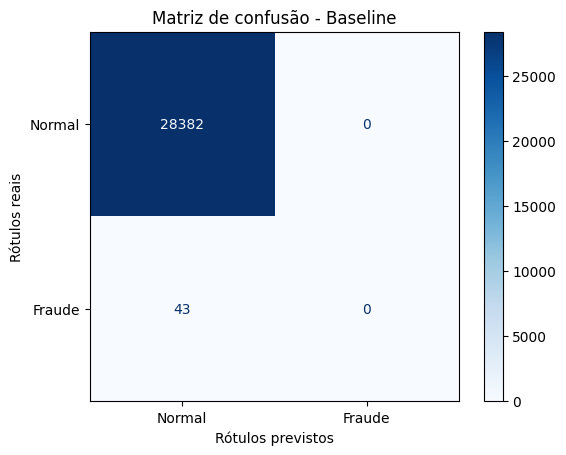

In [36]:
modelo_baseline = DummyClassifier(strategy="prior").fit(X_treino, y_treino)

notas_baseline = pr_auc_cv(modelo_baseline)
print(f"\nBaseline - PR-AUC (CV): {notas_baseline.mean():.4f} ± {notas_baseline.std():.4f}")

disp = ConfusionMatrixDisplay.from_predictions(
    y_teste, modelo_baseline.predict(X_teste),
    display_labels=["Normal", "Fraude"], values_format="d", cmap="Blues",
)
disp.ax_.set(
    xlabel="Rótulos previstos",
    ylabel="Rótulos reais",
    title="Matriz de confusão - Baseline",
);

### Funções para uso do Optuna e explicação da subamostragem controlada pelo Optuna e redução de dimensionalidade

**Subamostragem como hiperparâmetro.** Com cerca de 0,17% de fraudes, muitos algoritmos tendem a ignorar a classe minoritária. Em vez de fixar uma técnica de balanceamento, usamos o `RandomUnderSampler`, que remove aleatoriamente exemplos normais apenas no treino de cada fold. 

O parâmetro razao_amostragem (entre 0,01 e 1, escala logarítmica) define a razão fraude/normal após a subamostragem: 1 significa classes iguais e 0,01 significa 100 normais para cada fraude. O Optuna escolhe esse valor por algoritmo, e a subamostragem também deixa o treino muito mais rápido. Como ela distorce as probabilidades previstas, o limiar de decisão é recalibrado ao final.

**Redução de dimensionalidade/seleção de atributos.** O hiperparâmetro "reducao" assume um de três valores: "nenhuma", "pca" (com `pca_n_componentes` entre 5 e 28) ou "selecao" (`SelectKBest` com teste F, `selecao_k` entre 5 e 28). Como os atributos `V1`–`V28` já são componentes principais anonimizados, é interessante verificar se um PCA adicional ou a seleção de atributos ajudam.

In [39]:
N_ATRIBUTOS = len(ATRIBUTOS)


def cria_reducao(trial):    
    """Cria a etapa de redução de dimensionalidade do pipeline.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de PCA, uma instância de SelectKBest ou a string
      "passthrough" (sem redução), conforme sorteado pelo optuna.
    """
    
    tipo = trial.suggest_categorical("reducao", ["nenhuma", "pca", "selecao"])
    if tipo == "pca":
        n = trial.suggest_int("pca_n_componentes", 5, N_ATRIBUTOS)
        return PCA(n_components=n, random_state=SEMENTE_ALEATORIA)
    if tipo == "selecao":
        k = trial.suggest_int("selecao_k", 5, N_ATRIBUTOS)
        return SelectKBest(score_func=f_classif, k=k)
    return "passthrough"


def cria_pipeline(trial, cria_modelo):
    """Cria o pipeline completo (padronização, subamostragem, redução, modelo).

    A subamostragem (RandomUnderSampler) faz parte do pipeline de imblearn,
    logo é aplicada apenas nos dados de treino de cada fold, evitando
    vazamento de dados.

    Args:
      trial: objeto tipo Trial do optuna.
      cria_modelo: função que recebe o trial e retorna o classificador.

    Returns:
      Uma instância de ImbPipeline.
    """
    
    razao = trial.suggest_float("razao_amostragem", 0.003, 1.0, log=True)
    return ImbPipeline([
        ("padronizacao", StandardScaler()),
        ("amostragem", RandomUnderSampler(sampling_strategy=razao, random_state=SEMENTE_ALEATORIA)),
        ("reducao", cria_reducao(trial)),
        ("modelo", cria_modelo(trial)),
    ])


# Espaços de busca de cada algoritmo

def modelo_logistica_optuna(trial):
    """Cria uma Regressão Logística com hiperparâmetros sorteados pelo optuna.

    Espaço de busca: C (escala logarítmica, 1e-4 a 1e2).

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de LogisticRegression.
    """
    return LogisticRegression(
        C=trial.suggest_float("C", 1e-4, 1e2, log=True),
        max_iter=2000, random_state=SEMENTE_ALEATORIA,
    )


def modelo_knn_optuna(trial):
    """Cria um KNN com hiperparâmetros sorteados pelo optuna.

    Espaço de busca: número de vizinhos (3 a 30), pesos (uniform ou
    distance) e potência da distância de Minkowski (1 ou 2).

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de KNeighborsClassifier.
    """
    
    return KNeighborsClassifier(
        n_neighbors=trial.suggest_int("n_neighbors", 3, 30),
        weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
        p=trial.suggest_int("p", 1, 2),
        n_jobs=1,
    )


def modelo_rf_optuna(trial):
    """Cria uma Floresta Aleatória com hiperparâmetros sorteados pelo optuna.

    Espaço de busca: número de árvores (50 a 150), profundidade máxima
    (3 a 20), mínimo de exemplos por folha (1 a 20) e número máximo de
    atributos por divisão (sqrt, log2 ou 0,5).

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de RandomForestClassifier.
    """
    
    return RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 150),
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
        max_features=trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
        n_jobs=1, random_state=SEMENTE_ALEATORIA,
    )


def modelo_hgb_optuna(trial):
    """Cria um Hist Gradient Boosting com hiperparâmetros sorteados pelo optuna.

    Espaço de busca: taxa de aprendizado (0,01 a 0,3, log), número de
    iterações (50 a 300), máximo de folhas (8 a 64), mínimo de exemplos
    por folha (5 a 50) e regularização L2 (1e-6 a 10, log).

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de HistGradientBoostingClassifier.
    """
    
    return HistGradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_iter=trial.suggest_int("max_iter", 50, 300),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 64),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 50),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-6, 10.0, log=True),
        random_state=SEMENTE_ALEATORIA,
    )


def modelo_mlp_optuna(trial):
    """Cria um MLP com hiperparâmetros sorteados pelo optuna.

    A arquitetura é definida por número de camadas ocultas (1 a 3) e
    número de neurônios por camada (16 a 128, o mesmo em todas as camadas).
    Também são sorteados a regularização alpha (1e-6 a 1e-1, log) e a taxa
    de aprendizado inicial (1e-4 a 1e-2, log). Usa early stopping.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância de MLPClassifier.
    """
    
    n_camadas = trial.suggest_int("n_camadas", 1, 3)
    neuronios = trial.suggest_int("neuronios", 16, 128)
    return MLPClassifier(
        hidden_layer_sizes=(neuronios,) * n_camadas,
        alpha=trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
        max_iter=100, early_stopping=True, random_state=SEMENTE_ALEATORIA,
    )


MODELOS = {
    "Regressão Logística": modelo_logistica_optuna,
    "KNN": modelo_knn_optuna,
    "Random Forest": modelo_rf_optuna,
    "Hist. Gradient Boosting": modelo_hgb_optuna,
    "MLP": modelo_mlp_optuna,
}

### Otimização com Optuna

Para cada algoritmo é criado um estudo do Optuna (amostrador TPE, com semente aleatória fixa) que maximiza a PR-AUC média na validação cruzada ao longo de 100 tentativas. Em cada tentativa o Optuna sorteia, ao mesmo tempo, os hiperparâmetros do modelo, a razão de subamostragem e a estratégia de redução de dimensionalidade.

In [18]:
N_TRIALS = 100


def cria_objetivo(cria_modelo):
    def objetivo(trial):
        pipeline = cria_pipeline(trial, cria_modelo)
        notas = pr_auc_cv(pipeline)
        trial.set_user_attr("pr_auc_folds", notas.tolist())
        return float(notas.mean())
    return objetivo


estudos = {}
for nome, cria_modelo in MODELOS.items():
    NOME_DO_ESTUDO = nome.lower().replace(" ", "_").replace(".", "").replace("ã", "a").replace("ç", "c")

    estudo = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=SEMENTE_ALEATORIA),
        study_name=NOME_DO_ESTUDO,
        storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
        load_if_exists=True,
    )

    concluidas = len(estudo.get_trials(states=[optuna.trial.TrialState.COMPLETE]))
    faltam = N_TRIALS - concluidas
    if faltam > 0:
        estudo.optimize(cria_objetivo(cria_modelo), n_trials=faltam, show_progress_bar=True)

    estudos[nome] = estudo
    print(f"{nome}: melhor PR-AUC (CV) = {estudo.best_value:.4f} | {estudo.best_params}")

Regressão Logística: melhor PR-AUC (CV) = 0.7676 | {'razao_amostragem': 0.006429454373539559, 'reducao': 'selecao', 'selecao_k': 23, 'C': 24.71744152787143}
KNN: melhor PR-AUC (CV) = 0.8346 | {'razao_amostragem': 0.0032857217525987, 'reducao': 'selecao', 'selecao_k': 12, 'n_neighbors': 28, 'weights': 'distance', 'p': 1}
Random Forest: melhor PR-AUC (CV) = 0.8382 | {'razao_amostragem': 0.0030271392717140084, 'reducao': 'nenhuma', 'n_estimators': 97, 'max_depth': 9, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Hist. Gradient Boosting: melhor PR-AUC (CV) = 0.8436 | {'razao_amostragem': 0.0037345086397784183, 'reducao': 'selecao', 'selecao_k': 23, 'learning_rate': 0.027053816280847673, 'max_iter': 119, 'max_leaf_nodes': 52, 'min_samples_leaf': 14, 'l2_regularization': 5.726496767990831e-06}
MLP: melhor PR-AUC (CV) = 0.8405 | {'razao_amostragem': 0.003811856026714541, 'reducao': 'pca', 'pca_n_componentes': 25, 'n_camadas': 3, 'neuronios': 120, 'alpha': 1.835786001705531e-06, 'learning_rat

### Tentativas do Optuna

As tabelas abaixo mostram as melhores tentativas de cada algoritmo, ordenadas pela PR-AUC média na validação cruzada. Cada linha é uma combinação de hiperparâmetros testada pelo Optuna:

- **tentativa:** número da tentativa no estudo, começando em 0.
- **PR-AUC (CV):** média da PR-AUC nos 5 folds.
- **reducao:** estratégia de redução de dimensionalidade sorteada ("nenhuma", "pca" ou "selecao").
- **n_atributos:** quantidade de atributos que chegam ao modelo. Sem redução são os 28 atributos originais. Com seleçao, são os k atributos mantidos. Com pca, são os componentes principais, que são combinações dos 28 atributos originais.
- **razao_amostragem:** razão fraude/normal no treino após a subamostragem da classe majoritária.
- **Demais colunas:** hiperparâmetros do próprio algoritmo.

Valores `NaN` aparecem quando um parâmetro não se aplica à tentativa. Por exemplo, `pca_n_componentes` só existe quando a redução sorteada foi `pca`.

Esta visão permite ver quais estratégias aparecem entre as melhores tentativas de cada algoritmo, por exemplo se as melhores tentativas usam redução de dimensionalidade ou todos os atributos, e quais razões de subamostragem predominam.

In [14]:
def tabela_tentativas(estudo):
    df = estudo.trials_dataframe()
    df = df[df["state"] == "COMPLETE"]
    colunas = ["number", "value"] + [c for c in df.columns if c.startswith("params_")]
    df = df[colunas].rename(columns={"number": "tentativa", "value": "PR-AUC (CV)"})
    df.columns = [c.replace("params_", "") for c in df.columns]

    df["n_atributos"] = np.select(
        [df["reducao"] == "pca", df["reducao"] == "selecao"],
        [df["pca_n_componentes"], df["selecao_k"]],
        default=len(ATRIBUTOS),
    ).astype(int)

    cols = list(df.columns)
    cols.remove("n_atributos")
    cols.insert(cols.index("reducao") + 1, "n_atributos")
    df = df[cols]

    return df.sort_values("PR-AUC (CV)", ascending=False).reset_index(drop=True)

melhores = []
for nome, e in estudos.items():
    t = tabela_tentativas(e).iloc[0]        
    melhores.append({
        "Algoritmo": nome,
        "Tentativa": int(t["tentativa"]),
        "PR-AUC (CV)": t["PR-AUC (CV)"],
        "Redução": t["reducao"],
        "Nº atributos": int(t["n_atributos"]),
        "Razão amostragem": t["razao_amostragem"],
    })

tabela_melhores = pd.DataFrame(melhores).set_index("Algoritmo").sort_values("PR-AUC (CV)", ascending=False)

display(
    tabela_melhores.style
    .format({"PR-AUC (CV)": "{:.4f}", "Razão amostragem": "{:.4f}"})
    .background_gradient(subset=["PR-AUC (CV)"], cmap="Greens")
)

,Tentativa,PR-AUC (CV),Redução,Nº atributos,Razão amostragem
Algoritmo,,,,,
Hist. Gradient Boosting,75,0.8436,selecao,23,0.0037
MLP,92,0.8405,pca,25,0.0038
Random Forest,69,0.8382,nenhuma,29,0.0030
KNN,98,0.8346,selecao,12,0.0033
Regressão Logística,84,0.7676,selecao,23,0.0064


### Resultados da Validação Cruzada

A tabela resume o melhor conjunto de hiperparâmetros de cada algoritmo, comparado ao baseline nos mesmos folds. Os gráficos mostram a distribuição da PR-AUC entre as 100 tentativas de cada algoritmo e o efeito médio de cada estratégia de redução de dimensionalidade.

,PR-AUC CV (média),PR-AUC CV (desvio),Redução,Nº atributos,Razão amostragem
Algoritmo,,,,,
Baseline (Dummy),0.0018,0.0001,-,NaN,NaN
Regressão Logística,0.7676,0.0451,selecao (23),23.0,0.0064
KNN,0.8346,0.0443,selecao (12),12.0,0.0033
Random Forest,0.8382,0.0443,nenhuma,29.0,0.0030
Hist. Gradient Boosting,0.8436,0.0361,selecao (23),23.0,0.0037
MLP,0.8405,0.0295,pca (25),25.0,0.0038


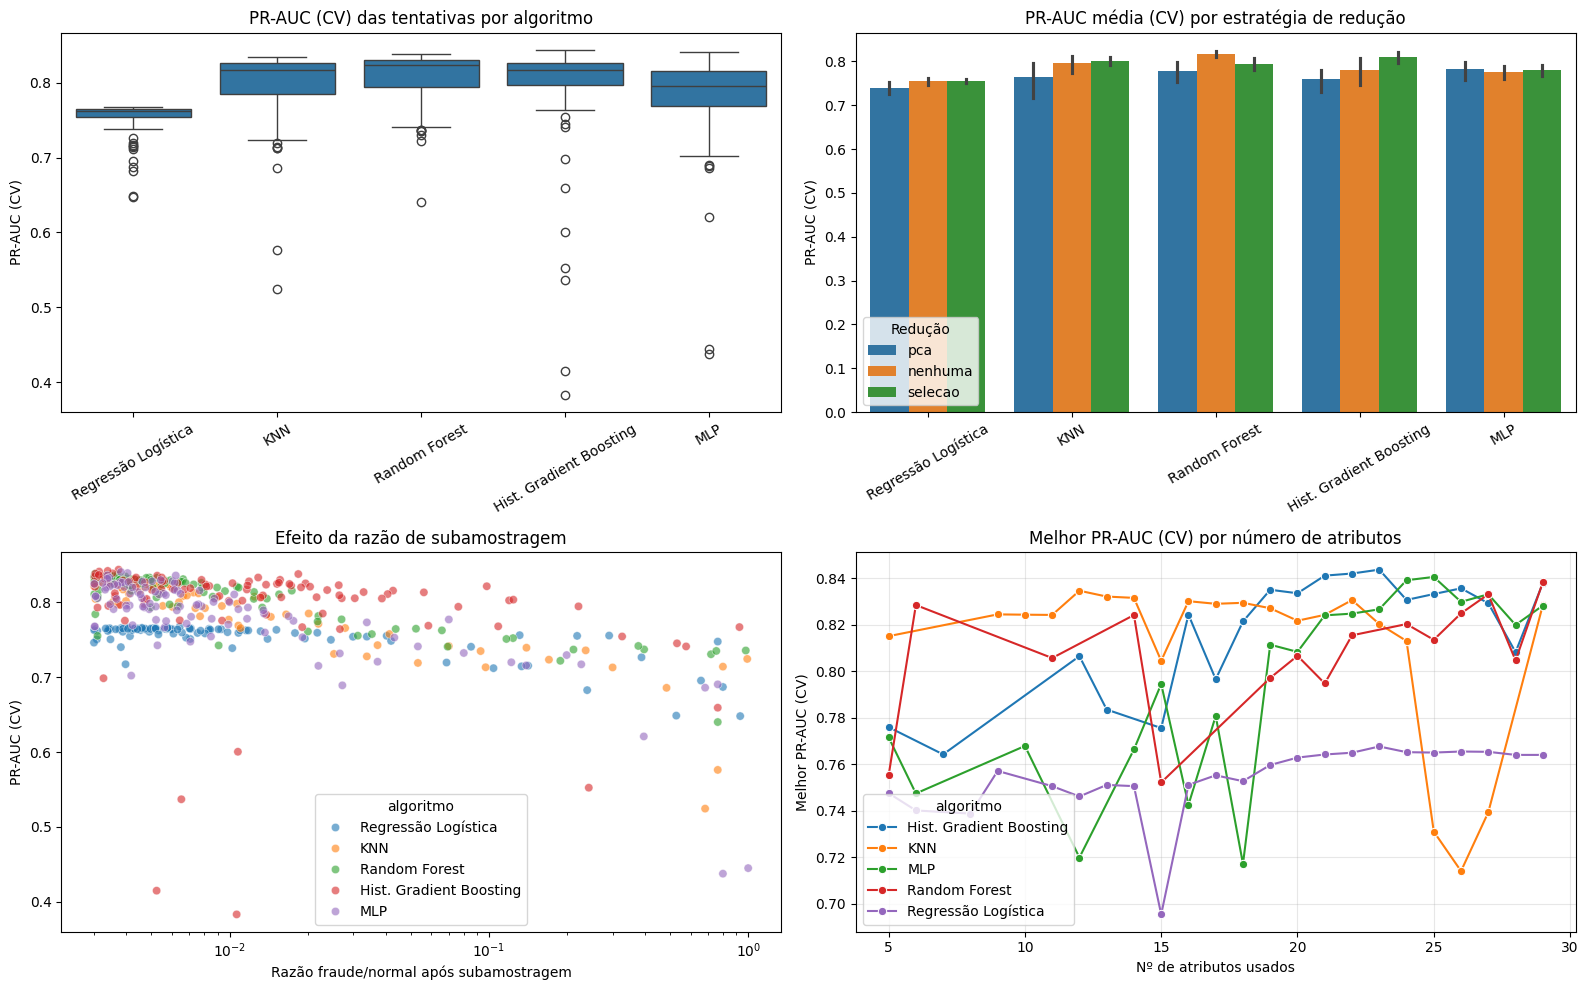

In [15]:
linhas = [{
    "Algoritmo": "Baseline (Dummy)",
    "PR-AUC CV (média)": notas_baseline.mean(),
    "PR-AUC CV (desvio)": notas_baseline.std(),
    "Redução": "-", "Nº atributos": np.nan, "Razão amostragem": np.nan,
}]
for nome, e in estudos.items():
    bp = e.best_params
    n_atr = (bp["pca_n_componentes"] if bp["reducao"] == "pca"
             else bp["selecao_k"] if bp["reducao"] == "selecao"
             else len(ATRIBUTOS))
    linhas.append({
        "Algoritmo": nome,
        "PR-AUC CV (média)": e.best_value,
        "PR-AUC CV (desvio)": np.std(e.best_trial.user_attrs["pr_auc_folds"]),
        "Redução": bp["reducao"] + (f" ({bp.get('pca_n_componentes', bp.get('selecao_k', ''))})"
                                    if bp["reducao"] != "nenhuma" else ""),
        "Nº atributos": n_atr,
        "Razão amostragem": bp["razao_amostragem"],
    })
tabela_cv = pd.DataFrame(linhas).set_index("Algoritmo")
display(tabela_cv.round(4))

df_trials = pd.concat(
    [e.trials_dataframe().assign(algoritmo=nome) for nome, e in estudos.items()],
    ignore_index=True,
)
df_trials = df_trials[df_trials["state"] == "COMPLETE"].copy()

# Garante que as colunas existam mesmo se alguma estratégia nunca foi sorteada
for col in ["params_pca_n_componentes", "params_selecao_k"]:
    if col not in df_trials:
        df_trials[col] = np.nan

df_trials["n_atributos"] = np.select(
    [df_trials["params_reducao"] == "pca", df_trials["params_reducao"] == "selecao"],
    [df_trials["params_pca_n_componentes"], df_trials["params_selecao_k"]],
    default=len(ATRIBUTOS),
).astype(int)

melhor_por_n = (df_trials.groupby(["algoritmo", "n_atributos"])["value"].max().reset_index())

fig, eixos = plt.subplots(2, 2, figsize=(16, 10))
eixos = eixos.ravel()

sns.boxplot(data=df_trials, x="algoritmo", y="value", ax=eixos[0])
eixos[0].set_title("PR-AUC (CV) das tentativas por algoritmo")
eixos[0].set_xlabel(""); eixos[0].set_ylabel("PR-AUC (CV)")
eixos[0].tick_params(axis="x", rotation=30)

sns.barplot(data=df_trials, x="algoritmo", y="value", hue="params_reducao", ax=eixos[1])
eixos[1].set_title("PR-AUC média (CV) por estratégia de redução")
eixos[1].set_xlabel(""); eixos[1].set_ylabel("PR-AUC (CV)")
eixos[1].tick_params(axis="x", rotation=30)
eixos[1].legend(title="Redução")

sns.scatterplot(data=df_trials, x="params_razao_amostragem", y="value",
                hue="algoritmo", alpha=0.6, ax=eixos[2])
eixos[2].set_xscale("log")
eixos[2].set_title("Efeito da razão de subamostragem")
eixos[2].set_xlabel("Razão fraude/normal após subamostragem"); eixos[2].set_ylabel("PR-AUC (CV)")

sns.lineplot(data=melhor_por_n, x="n_atributos", y="value",
             hue="algoritmo", marker="o", ax=eixos[3])
eixos[3].set_title("Melhor PR-AUC (CV) por número de atributos")
eixos[3].set_xlabel("Nº de atributos usados"); eixos[3].set_ylabel("Melhor PR-AUC (CV)")
eixos[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Avaliação no Conjunto de Teste

Cada pipeline com os melhores hiperparâmetros é reajustado em todo o conjunto de treino e avaliado uma única vez no teste. O modelo final é escolhido pela **PR-AUC na validação cruzada**, e não pelo desempenho no teste, para evitar escolher o modelo olhando o teste. Como a subamostragem altera as probabilidades previstas, a precisão e o recall com o limiar padrão de 0,5 tendem a ser pouco representativos, e por isso eles são reportados junto com a PR-AUC, que não depende de limiar.

In [16]:
pipelines_finais = {}
linhas_teste = []

for nome, e in estudos.items():
    pipe = cria_pipeline(optuna.trial.FixedTrial(e.best_params), MODELOS[nome])
    pipe.fit(X_treino, y_treino)
    pipelines_finais[nome] = pipe

    score = pipe.predict_proba(X_teste)[:, 1]
    pred = (score >= 0.5).astype(int)
    linhas_teste.append({
        "Algoritmo": nome,
        "PR-AUC (CV)": e.best_value,
        "PR-AUC (teste)": average_precision_score(y_teste, score),
        "Precisão (teste, limiar 0,5)": precision_score(y_teste, pred, zero_division=0),
        "Recall (teste, limiar 0,5)": recall_score(y_teste, pred),
    })

score_base = modelo_baseline.predict_proba(X_teste)[:, 1]
linhas_teste.insert(0, {
    "Algoritmo": "Baseline (Dummy)",
    "PR-AUC (CV)": notas_baseline.mean(),
    "PR-AUC (teste)": average_precision_score(y_teste, score_base),
    "Precisão (teste, limiar 0,5)": 0.0, "Recall (teste, limiar 0,5)": 0.0,
})
tabela_teste = pd.DataFrame(linhas_teste).set_index("Algoritmo")
display(tabela_teste.round(4))

melhor_nome = max(estudos, key=lambda n: estudos[n].best_value)
print(f"Melhor algoritmo segundo a validação cruzada: {melhor_nome}")

,PR-AUC (CV),PR-AUC (teste),"Precisão (teste, limiar 0,5)","Recall (teste, limiar 0,5)"
Algoritmo,,,,
Baseline (Dummy),0.0018,0.0015,0.0000,0.0000
Regressão Logística,0.7676,0.7487,0.8140,0.8140
KNN,0.8346,0.8078,0.9000,0.8372
Random Forest,0.8382,0.8422,0.9211,0.8140
Hist. Gradient Boosting,0.8436,0.8395,0.9211,0.8140
MLP,0.8405,0.7856,0.8780,0.8372


Melhor algoritmo segundo a validação cruzada: Hist. Gradient Boosting


### Ajuste do Limiar de Decisão do Melhor Modelo

Como falsos positivos são muito custosos neste problema (transações legítimas bloqueadas), o limiar do melhor modelo é escolhido maximizando o **F0,5**, que dá mais peso à precisão do que ao recall. O limiar é escolhido apenas com **previsões fora da amostra obtidas na validação cruzada do treino** e depois aplicado, sem alterações, ao conjunto de teste.

Limiar escolhido (F0.5 nos dados fora da amostra): 0.8828
PR-AUC      0.840
Precisão    0.971
Recall      0.767
F0.5        0.922
dtype: float64


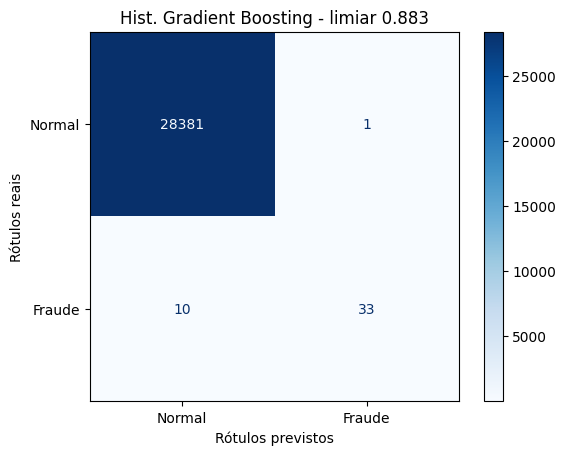

In [38]:
pipe_melhor = cria_pipeline(
    optuna.trial.FixedTrial(estudos[melhor_nome].best_params), MODELOS[melhor_nome]
)

oof = np.zeros(len(y_treino))
for idx_tr, idx_va in FOLDS:
    m = clone(pipe_melhor).fit(X_treino[idx_tr], y_treino[idx_tr])
    oof[idx_va] = m.predict_proba(X_treino[idx_va])[:, 1]

BETA = 0.5
prec, rec, limiares = precision_recall_curve(y_treino, oof)

f_beta = (1 + BETA**2) * prec * rec / (BETA**2 * prec + rec + 1e-12)
limiar = limiares[np.argmax(f_beta[:-1])]

print(f"Limiar escolhido (F{BETA} nos dados fora da amostra): {limiar:.4f}")

score_teste = pipelines_finais[melhor_nome].predict_proba(X_teste)[:, 1]
pred_teste = (score_teste >= limiar).astype(int)

print(pd.Series({
    "PR-AUC": average_precision_score(y_teste, score_teste),
    "Precisão": precision_score(y_teste, pred_teste, zero_division=0),
    "Recall": recall_score(y_teste, pred_teste),
    f"F{BETA}": fbeta_score(y_teste, pred_teste, beta=BETA),
}).round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_teste, pred_teste,
    display_labels=["Normal", "Fraude"], values_format="d", cmap="Blues",
)
disp.ax_.set(
    xlabel="Rótulos previstos",
    ylabel="Rótulos reais",
);

plt.title(f"{melhor_nome} - limiar {limiar:.3f}")
plt.show()

## Conclusão e Aprendizados

Neste trabalho foram comparados cinco algoritmos (Regressão Logística, KNN, Random Forest, Hist. Gradient Boosting e MLP) na detecção de fraudes em cartões de crédito. Cada um teve seus hiperparâmetros, o grau de subamostragem e a estratégia de redução de dimensionalidade otimizados pelo Optuna, com validação cruzada estratificada e agrupada de 5 folds e PR-AUC como métrica.

**Resultados.** Todos os modelos superaram com folga o baseline (PR-AUC de 0,0018 na validação cruzada). O Hist. Gradient Boosting obteve a maior PR-AUC na validação cruzada (0,844) e foi escolhido por esse critério. Random Forest (0,838) e MLP (0,841) ficaram muito próximos, e a Regressão Logística teve o pior desempenho (0,768). Como os desvios-padrão entre folds (0,03 a 0,05) são maiores que as diferenças entre os quatro melhores modelos, eles não podem ser considerados claramente distintos. No teste, o Random Forest (0,842) e o Hist. Gradient Boosting (0,840) tiveram desempenho praticamente igual, enquanto o MLP caiu para 0,786, indicando maior instabilidade.

**Limiar de decisão.** Como bloquear transações legítimas é custoso, o limiar do melhor modelo foi ajustado para maximizar o F0,5, usando apenas previsões fora da amostra da validação cruzada. No teste, com limiar de 0,883, o modelo atingiu precisão de 0,971, recall de 0,767 e F0,5 de 0,922. Isso corresponde a 33 das 43 fraudes detectadas, com apenas 1 falso positivo. Esse ganho de precisão foi obtido ao custo de deixar passar mais fraudes em relação ao limiar de 0,5 (recall de 0,814).

**Aprendizados.**
- A subamostragem da classe majoritária tratada como hiperparâmetro funcionou bem: todos os modelos convergiram para razões fraude/normal baixas (cerca de 0,3% a 0,6%), o que também acelerou o treino.
- A redução de dimensionalidade não trouxe ganho consistente. Como V1–V28 já são componentes principais, os melhores pipelines usaram seleção de atributos ou nenhuma redução, e só o MLP usou PCA.
- A PR-AUC foi mais informativa que a acurácia, que seria altíssima mesmo para um modelo que nunca detecta fraudes.
- Agrupar linhas quase idênticas evitou vazamento entre treino e teste, e escolher o modelo e o limiar sem usar o conjunto de teste deixou a avaliação final mais confiável.

**Limitações.** O conjunto de teste tem apenas 43 fraudes, então as métricas finais têm grande incerteza (um único acerto ou erro altera o recall em cerca de 2,3 pontos percentuais). Além disso, os atributos anonimizados impedem interpretar o que o modelo aprendeu. Trabalhos futuros poderiam incluir `Time`, testar outras técnicas de balanceamento (como SMOTE ou pesos de classe), explorar outros modelos de boosting e avaliar o custo financeiro real de cada tipo de erro para escolher o limiar.

## Descrição do uso de IA neste trabalho

Este trabalho utilizou IA para auxiliar na busca por um dataframe de fraudes bancarias, na melhora da formatação da introdução, na realização de gráficos para visualizar o desbalanceamento dos dados, na montagem dos markdonwns de: PR-AUC, F0.5, Hist Gradient Boosting e MLP. Ela auxiliou também na correção do código das funções: `_nota_fold`, `pr_auc_cv`, `modelo_hgb_optuna`, `modelo_mlp_optuna`, `cria_objetivo` e `tabela_tentativas`. Ela realizou o código dos gráficos presentes na seção: Resultados da Validação Cruzada e na formatação de todos os dataframes que mostraram os resultados. E na correção de erros neste notebook.

Links para as conversas: 
* [https://claude.ai/share/cb10b3cf-8ff8-46a9-9ff7-19ebb27c2758](https://claude.ai/share/cb10b3cf-8ff8-46a9-9ff7-19ebb27c2758)
* [https://claude.ai/share/464d58f3-ccf0-4a56-b2c8-5a76c24d72ed](https://claude.ai/share/464d58f3-ccf0-4a56-b2c8-5a76c24d72ed)
* [https://claude.ai/share/68fb5083-aa23-4b1a-a2c3-51d4b2382619](https://claude.ai/share/68fb5083-aa23-4b1a-a2c3-51d4b2382619)
* [https://claude.ai/share/8718d147-4f4c-4d70-a842-b5157fb00ce2](https://claude.ai/share/8718d147-4f4c-4d70-a842-b5157fb00ce2)

## Referências


Cadernos disponibilizadois na disciplina de Aprendizado de Máquina:

    - 1.1 - Tratamento de dados com pandas
    - 2.1 - Aprendizado de máquina, k-NN e métricas
    - 2.2 - Divisão de dados em treino e 
    - 3.0 - Modelo linear e baseline
    - 4.0 - Árvore de decisão e floresta
    - 5.0 - Classificação
    - 6.0 - Validação cruzada e otimização de hiperparâmetros
    - 6.1 - Vazamento de dados
    - 7.0 - Dados sintéticos e pipeline
    - 7.1 - Otimização de hiperparâmetros com optuna
    - 8.1 - Seleção de atributos
    - 9.0 - Outras métricas e outros tipos de classificação

Link do Dataset:

* [https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data)